# Week 04 Lab + Assignment
## Reverse Diffusion Diagnostics — Did My DDPM Learn More Than Gaussian?

Week 03의 실제 주식 pair와 frozen checkpoint를 이용해 **재학습 없이 진단**합니다.

> **내 DDPM은 Gaussian benchmark보다 실제로 더 많은 금융분포 구조를 학습했는가?**

실습과 과제는 이 Notebook 하나에 통합되어 있습니다.

## State / Step Contract
- `states[t] = x_t`, $t=0,\ldots,T$
- `alpha_bar_full[0] = 1`
- reverse $x_t\rightarrow x_{t-1}$의 parameter index는 `k=t-1`
- $\bar\alpha_t$: signal variance fraction
- $\sqrt{\bar\alpha_t}$: signal amplitude coefficient

In [55]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
SEED=202604
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:",torch.__version__); print("Device :",device)
if device.type=="cuda": print("GPU    :",torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cpu
Device : cpu


In [56]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self,dim=32): super().__init__(); self.dim=dim
    def forward(self,t):
        h=self.dim//2
        f=torch.exp(-np.log(10000.)*torch.arange(h,device=t.device,dtype=torch.float32)/max(h-1,1))
        a=t.float().unsqueeze(1)*f.unsqueeze(0)
        return torch.cat([torch.sin(a),torch.cos(a)],1)
class NoisePredictor(nn.Module):
    def __init__(self,time_dim=32,hidden_dim=128):
        super().__init__(); self.time_embedding=SinusoidalTimeEmbedding(time_dim)
        self.net=nn.Sequential(nn.Linear(2+time_dim,hidden_dim),nn.SiLU(),nn.Linear(hidden_dim,hidden_dim),nn.SiLU(),nn.Linear(hidden_dim,2))
    def forward(self,x,t): return self.net(torch.cat([x,self.time_embedding(t)],1))

# Part 0. 실제 데이터와 checkpoint 불러오기

Instructor 실행본은 P01을 사용합니다. 학생용은 자기 CSV와 checkpoint를 같은 폴더에 둡니다.

In [57]:
csvs=sorted(Path(".").glob("Diffusion_week03_*_P*.csv"))
ckpts=sorted(Path(".").glob("Diffusion_week04_*_P*.pt"))
assert len(csvs)==1 and len(ckpts)==1, "자기 CSV와 checkpoint 각 1개를 Notebook과 같은 폴더에 두세요."
data_path,checkpoint_path=csvs[0],ckpts[0]
df=pd.read_csv(data_path,parse_dates=["Date"]); raw=df[["Asset_1","Asset_2"]].to_numpy(float)
mu=raw.mean(0); sigma=raw.std(0); z_np=((raw-mu)/sigma).astype(np.float32); xall=torch.tensor(z_np,device=device)
p=torch.load(checkpoint_path,map_location=device); mc=p["model_config"]; cfg=p["diffusion_config"]
model=NoisePredictor(mc["time_embed_dim"],mc["hidden_dim"]).to(device); model.load_state_dict(p["model_state_dict"]); model.eval()
T=int(cfg["T"]); betas=torch.linspace(float(cfg["beta_start"]),float(cfg["beta_end"]),T,device=device)
alphas=1-betas; alpha_bars=torch.cumprod(alphas,0); alpha_bar_full=torch.cat([torch.ones(1,device=device),alpha_bars])
print("Student:",p["student_id"],"Pair:",p["pair_id"],"N:",len(df),"Corr:",np.corrcoef(z_np.T)[0,1]); print("WEEK04_LOAD_PASS")

Student: 20225085 Pair: P06 N: 2631 Corr: 0.7559270425654502
WEEK04_LOAD_PASS


# Part 1. SNR와 Error Amplification

### Predict 1
`t`가 증가하면 SNR과 A_t는 각각 어떻게 변할까요?

**[YOUR PREDICTION]**

SNR은 단조 감소할것이라고 예상합니다. $\mathrm{SNR}_t=\bar\alpha_t/(1-\bar\alpha_t)$이고 $\bar\alpha_t$는 $t$가 커질수록 계속 줄어들기 때문입니다. 

A_t는 단조 증가할 것이라고 예상합니다. 복원식에서 $\hat x_0-x_0=-\sqrt{(1-\bar\alpha_t)/\bar\alpha_t}\,(\hat\epsilon-\epsilon)$이므로 $A_t=\sqrt{(1-\bar\alpha_t)/\bar\alpha_t}=1/\sqrt{\mathrm{SNR}_t}$이고, SNR과 정확히 반대로 움직이기 때문입니다. 

### Coding Task 1
SNR과 A_t를 직접 구현하세요.

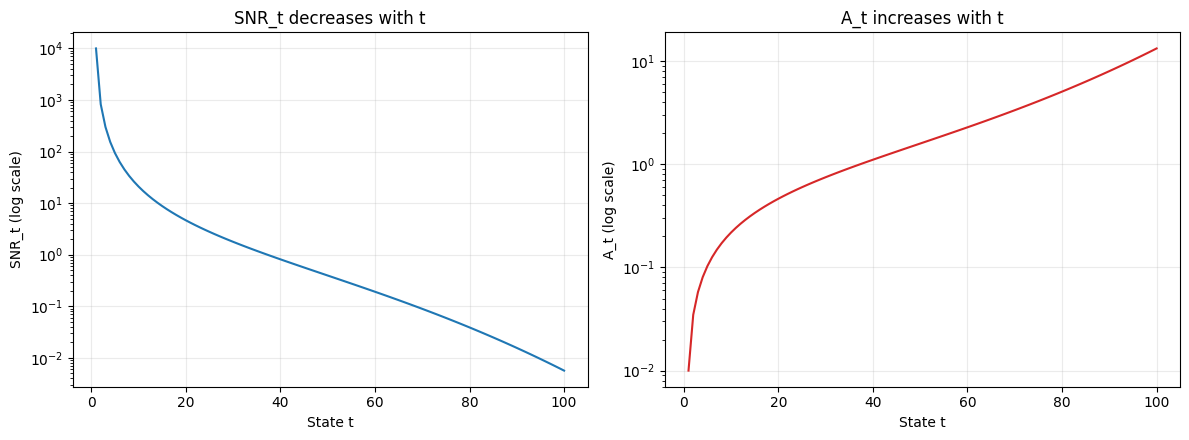

,state_t,alpha_bar,SNR,A_t
0,1,0.999900,9997.340820,0.010001
1,10,0.954508,20.981775,0.218313
2,30,0.639914,1.777116,0.750140
3,50,0.282981,0.394663,1.591794
4,70,0.081817,0.089108,3.349977
5,90,0.015324,0.015563,8.015973
6,100,0.005619,0.005651,13.303203


SNR strictly decreasing : True
A_t strictly increasing : True
A_t == 1/sqrt(SNR)      : True
alpha_bar_T= 0.005618760362267494
SNR_T= 0.005650509
A_T= 13.303203


In [ ]:
states=np.arange(1,T+1)
ab_np=alpha_bar_full[1:].detach().cpu().numpy()

# TODO 1-A
snr = ab_np / (1 - ab_np)
# TODO 1-B
A = np.sqrt((1 - ab_np) / ab_np)
assert snr is not None and A is not None

# t 증가에 따른 SNR / A_t 변화 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(states, snr, color='tab:blue')
axes[0].set_yscale('log'); axes[0].set_xlabel('State t'); axes[0].set_ylabel('SNR_t (log scale)')
axes[0].set_title('SNR_t decreases with t'); axes[0].grid(alpha=.25)
axes[1].plot(states, A, color='tab:red')
axes[1].set_yscale('log'); axes[1].set_xlabel('State t'); axes[1].set_ylabel('A_t (log scale)')
axes[1].set_title('A_t increases with t'); axes[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

# 선택한 state에서의 값 비교
sel = [1, 10, 30, 50, 70, 90, 100]
sel = [s for s in sel if s <= T]
snr_table = pd.DataFrame({'state_t': sel,
                          'alpha_bar': ab_np[np.array(sel) - 1],
                          'SNR': snr[np.array(sel) - 1],
                          'A_t': A[np.array(sel) - 1]})
display(snr_table)

# 단조성 및 관계식 검증
print('SNR strictly decreasing :', bool(np.all(np.diff(snr) < 0)))
print('A_t strictly increasing :', bool(np.all(np.diff(A) > 0)))
print('A_t == 1/sqrt(SNR)      :', bool(np.allclose(A, 1/np.sqrt(snr))))
print('alpha_bar_T=',float(alpha_bar_full[T])); print('SNR_T=',snr[-1]); print('A_T=',A[-1])


### 결과해석
실제 결과, SNR은 t=1에서 약 10⁴, t=100에서 0.0056까지 단조 감소했고, A_t는 0.01에서 13.3까지 단조 증가했다. SNR=1(A_t=1)이 되는 지점은 t≈38(A_37=0.991, A_38=1.029)이며, 이후부터 ε̂ 오차가 x̂₀에서 1배 이상 증폭된다. t=T에서는 13배 이상 증폭된다.

# Part 2. Oracle Reconstruction — Sanity Check

### Predict 2
True epsilon을 사용하면 timestep이 커져도 oracle RMSE는 어떻게 될까요?

**[YOUR PREDICTION]**

모든 timestep에서 oracle RMSE는 거의 0일 것입니다. 진짜 $\epsilon$을 넣으면
  $\hat x_0=\dfrac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon}{\sqrt{\bar\alpha_t}}=\dfrac{\sqrt{\bar\alpha_t}\,x_0}{\sqrt{\bar\alpha_t}}=x_0$
  가 되어, forward 식을 그대로 거꾸로 푸는 것이기 때문입니다.

### Coding Task 2
forward x_t와 oracle x0_hat을 직접 완성하세요.

In [59]:
rng=np.random.default_rng(SEED); ix=rng.integers(0,len(xall),2048)
x0=xall[torch.tensor(ix,device=device)]
eps=torch.tensor(rng.standard_normal((len(ix),2)),dtype=torch.float32,device=device)
rr=[]
for state_t in [10,30,50,70,90,100]:
    ab=alpha_bar_full[state_t]
    # TODO 2-A
    xt = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * eps
    # TODO 2-B
    x0_hat = (xt - torch.sqrt(1 - ab) * eps) / torch.sqrt(ab)
    assert xt is not None and x0_hat is not None
    rr.append([state_t,torch.sqrt(torch.mean((x0_hat-x0)**2)).item()])
oracle_table=pd.DataFrame(rr,columns=['state_t','oracle_rmse']); display(oracle_table)
assert oracle_table.oracle_rmse.max()<1e-4; print('ORACLE_PASS')

,state_t,oracle_rmse
0,10,2.688369e-08
1,30,5.137422e-08
2,50,5.603648e-08
3,70,9.721091e-08
4,90,2.079762e-07
5,100,3.450053e-07


ORACLE_PASS


### 결과해석
실제 결과, 모든 timestep(t=10~100)에서 oracle RMSE는 3×10⁻⁸ ~ 3.5×10⁻⁷로 사실상 0이었습니다. 진짜 ε을 넣으면 복원식이 forward 식의 정확한 역연산이 되어 x̂₀ = x₀가 되기 때문입니다. 남은 값은 float32 반올림 오차이며, t가 커질수록 √ᾱ_t로 나누는 효과(A_t 증가) 때문에 아주 조금 커졌습니다. 따라서 이후 Part에서 나타나는 큰 복원 오차는 구현 오류가 아니라 모델의 ε 예측 오차 때문입니다.


# Part 3. Neural vs Gaussian-Optimal Denoiser

### Predict 3
Neural denoiser가 모든 state에서 Gaussian보다 좋을까요? 큰 t에서 x0 RMSE가 1을 넘을 수 있을까요?

**[YOUR PREDICTION]**

모든 state에서 Gaussian보다 좋지는 않을 것입니다. Gaussian denoiser $E[\epsilon\mid x_t]=\sqrt{1-\bar\alpha_t}\,\Sigma_t^{-1}x_t$는 데이터가 정규분포라면 이론적으로 최선입니다. 신경망이 이 기준을 이기려면 정규분포에 없는 구조, 즉 P06의 fat tail(초과첨도 13.4, 7.3)을 활용해야 합니다.

### Coding Task 3
Gaussian benchmark를 직접 구현하세요.

,state_t,eps_nn,eps_gauss,x0_nn,x0_gauss
0,10,0.951395,0.956072,0.207702,0.208723
1,30,0.712686,0.737605,0.534614,0.553307
2,50,0.486602,0.508762,0.774571,0.809845
3,70,0.286014,0.286565,0.958142,0.959985
4,90,0.148666,0.126241,1.191700,1.011947
5,100,0.102800,0.076620,1.367573,1.019289


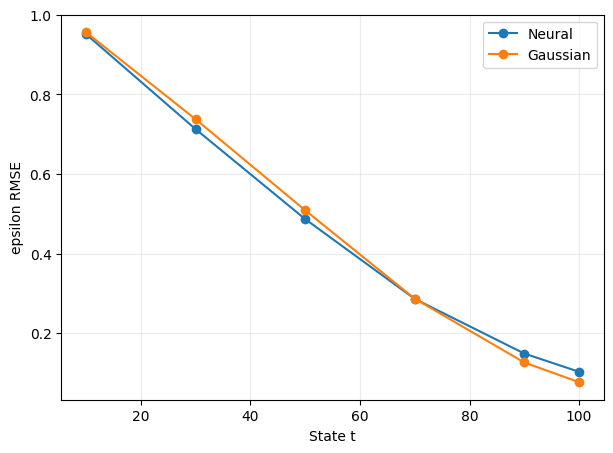

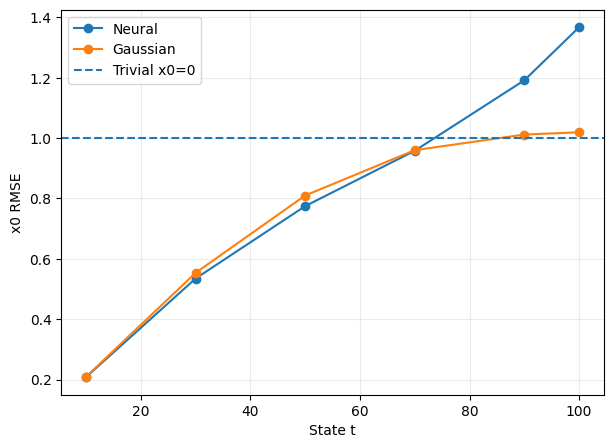

In [60]:
Rnp=np.corrcoef(z_np.T); R=torch.tensor(Rnp,dtype=torch.float32,device=device)
def geps(xt,s):
    q=alpha_bar_full[s]
    # TODO 3-A
    Sigma_t = q * R + (1 - q) * torch.eye(2, dtype=R.dtype, device=R.device)
    # TODO 3-B
    eps_gauss = torch.sqrt(1 - q) * (xt @ torch.linalg.inv(Sigma_t))
    assert Sigma_t is not None and eps_gauss is not None
    return eps_gauss

rr=[]
for s in [10,30,50,70,90,100]:
    q=alpha_bar_full[s]; xt=torch.sqrt(q)*x0+torch.sqrt(1-q)*eps; tv=torch.full((len(x0),),s-1,dtype=torch.long,device=device)
    with torch.no_grad(): en=model(xt,tv); eg=geps(xt,s)
    xn=(xt-torch.sqrt(1-q)*en)/torch.sqrt(q); xg=(xt-torch.sqrt(1-q)*eg)/torch.sqrt(q)
    rr.append([s,torch.sqrt(torch.mean((en-eps)**2)).item(),torch.sqrt(torch.mean((eg-eps)**2)).item(),torch.sqrt(torch.mean((xn-x0)**2)).item(),torch.sqrt(torch.mean((xg-x0)**2)).item()])
denoiser_table=pd.DataFrame(rr,columns=["state_t","eps_nn","eps_gauss","x0_nn","x0_gauss"]); display(denoiser_table)
plt.figure(figsize=(7,5)); plt.plot(denoiser_table.state_t,denoiser_table.eps_nn,"o-",label="Neural"); plt.plot(denoiser_table.state_t,denoiser_table.eps_gauss,"o-",label="Gaussian"); plt.xlabel("State t"); plt.ylabel("epsilon RMSE"); plt.legend(); plt.grid(alpha=.25); plt.show()
plt.figure(figsize=(7,5)); plt.plot(denoiser_table.state_t,denoiser_table.x0_nn,"o-",label="Neural"); plt.plot(denoiser_table.state_t,denoiser_table.x0_gauss,"o-",label="Gaussian"); plt.axhline(1,ls="--",label="Trivial x0=0"); plt.xlabel("State t"); plt.ylabel("x0 RMSE"); plt.legend(); plt.grid(alpha=.25); plt.show()

### Assignment 1
Neural $\epsilon_\theta$가 Gaussian보다 나은 state, $x_0$ RMSE가 1을 넘는 state, 그리고 “DDPM이 항상 Gaussian보다 우월하다”고 말할 수 없는 이유를 자신의 결과로 설명하세요.

**[YOUR ANSWER]**

**1. Neural ε_θ가 Gaussian보다 나은 state**

t=10, 30, 50에서 Neural의 ε RMSE가 Gaussian보다 낮았습니다.

| t | Neural | Gaussian |
|---|---|---|
| 10 | 0.951 | 0.956 |
| 30 | 0.713 | 0.738 |
| 50 | 0.487 | 0.509 |

t=70에서는 0.286 대 0.287로 사실상 동률이었습니다. 이 구간에서는 신경망이 Gaussian 가정에 없는 구조(P06의 fat tail)를 일부 반영한 것으로 보입니다. 다만 개선폭은 최대 약 4%로 작습니다.

**2. x₀ RMSE가 1을 넘는 state**

Neural는 t=70(0.958)에서는 1 미만이었고 t=90에서 1.19, t=100에서 1.37로 1을 넘었습니다. 측정점이 70과 90뿐이므로 교차점은 그 사이이며, 선형보간하면 약 t≈74입니다. x₀=0으로 예측하는 trivial 기준(RMSE=1)보다 나빠진 것입니다. 원인은 오차 증폭입니다. x₀ RMSE = A_t × ε RMSE이고, t=100에서 A_t=13.3이므로 ε 오차 0.103이 1.37로 증폭됩니다. Gaussian도 t=90, 100에서 1.012, 1.019로 1을 약간 넘었는데, 이론상 1 미만이어야 하므로 표본 오차가 증폭된 것으로 보입니다.

**3. "DDPM이 항상 Gaussian보다 우월하다"고 말할 수 없는 이유**

t=90, 100에서는 Neural의 ε RMSE(0.149, 0.103)가 Gaussian(0.126, 0.077)보다 컸습니다. x₀ RMSE도 Neural가 1.19, 1.37로 Gaussian의 1.01, 1.02보다 나빴습니다.
큰 t에서는 x_t가 거의 순수 노이즈(Σ_t≈I)라서 Gaussian 공식이 거의 정확한 반면, 신경망은 작은 잔여 오차가 남고 그것이 A_t로 증폭됩니다.
우세한 구간에서도 개선폭이 최대 4% 정도라서, DDPM이 Gaussian보다 훨씬 많은 구조를 학습했다고 보기 어렵습니다.
따라서 DDPM은 일부 state에서만 약간 우세하며, 전 구간에서 우월하다고 말할 수 없습니다.


# Part 4. One-shot Diagnosis — Contraction or Amplification?

### Predict 4
t가 커질수록 one-shot variance는 posterior benchmark에 가까워질까요, 아니면 model-error amplification으로 커질까요?

**[YOUR PREDICTION]**

작은~중간 $t$에서는 posterior benchmark에 가깝고, 큰 $t$에서는 amplification이 지배할 것 같습니다

### Coding Task 4
neural one-shot x0와 variance ratio를 직접 계산하세요.

,state_t,ratio_asset1,ratio_asset2
0,30,1.208232,0.924542
1,50,1.385321,0.887689
2,70,2.356728,1.322294
3,100,158.766075,63.281687


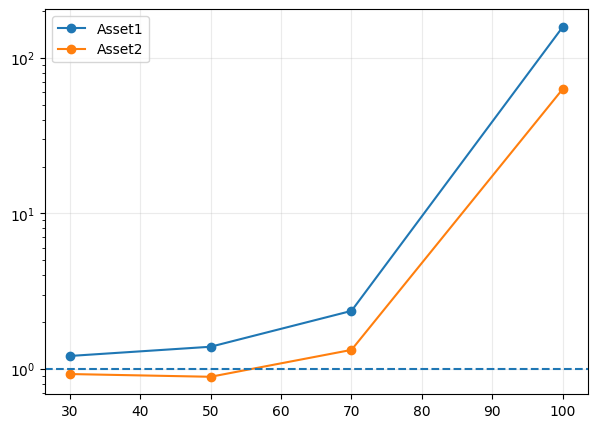

In [61]:
rr=[]
for s in [30,50,70,100]:
    q=alpha_bar_full[s]; xt=torch.sqrt(q)*x0+torch.sqrt(1-q)*eps; tv=torch.full((len(x0),),s-1,dtype=torch.long,device=device)
    with torch.no_grad(): en=model(xt,tv)
    # TODO 4-A
    xh = (xt - torch.sqrt(1 - q) * en) / torch.sqrt(q)
    assert xh is not None
    ov=xh.var(0,unbiased=False).cpu().numpy(); qv=float(q)
    S=qv*Rnp+(1-qv)*np.eye(2); bv=np.diag(qv*Rnp@np.linalg.inv(S)@Rnp)
    # TODO 4-B
    ratio_1 = ov[0] / bv[0]
    ratio_2 = ov[1] / bv[1]
    assert ratio_1 is not None and ratio_2 is not None
    rr.append([s,ratio_1,ratio_2])
one_table=pd.DataFrame(rr,columns=['state_t','ratio_asset1','ratio_asset2']); display(one_table)
plt.figure(figsize=(7,5)); plt.plot(one_table.state_t,one_table.ratio_asset1,'o-',label='Asset1'); plt.plot(one_table.state_t,one_table.ratio_asset2,'o-',label='Asset2'); plt.axhline(1,ls='--'); plt.yscale('log'); plt.legend(); plt.grid(alpha=.25); plt.show()

### Assignment 2
자신의 variance ratio를 이용하여 posterior-mean contraction과 model-error amplification 중 어느 현상이 지배적인지 진단하세요.

**[YOUR ANSWER]**

t=30, 50에서 variance ratio는 Asset 1이 1.21, 1.39, Asset 2가 0.92, 0.89로 1 근처이므로 posterior-mean 수축과 모델 오차가 대체로 균형을 이루는 구간입니다. t=70에서는 2.36, 1.32로 증폭이 시작되고, t=100에서는 158.8, 63.3으로 폭발합니다. t=100에서 사후평균의 분산은 약 0.009로 거의 0으로 수축해야 하지만, one-shot 추정값의 분산은 약 1.4(Asset 1)로 원본 분산 1을 넘었습니다. 이는 ε 예측 오차가 A_t=13.3배로 증폭된 것이며, 큰 t에서는 posterior-mean contraction이 아니라 model-error amplification이 지배적이라고 결론을 내릴 수 있습니다. 따라서 one-shot 복원은 큰 t에서 신뢰하기 어렵고, 반복적 reverse 과정이 필요한 이유가 됩니다. 

# Part 5. Iterative Reverse Trajectory

### Coding Task 5
reverse mean과 stochastic transition을 직접 구현하세요.

편차는 model error뿐 아니라 discretization, reverse variance specification, finite-sample error에서도 발생할 수 있습니다.

,state_t,corr_model,corr_theory,kurt1_model,kurt1_theory,kurt2_model,kurt2_theory
0,100,0.000650,0.004247,0.027101,0.000425,0.035793,0.000229
1,80,0.089461,0.028276,0.241703,0.018815,0.265873,0.010148
2,60,0.176473,0.121366,1.135995,0.346614,0.605053,0.186962
3,40,0.373581,0.339034,5.506104,2.704845,2.421393,1.458978
4,20,0.628759,0.621992,13.427094,9.103847,10.930698,4.910562
5,0,0.782271,0.755927,23.632044,13.446661,17.283712,7.253051


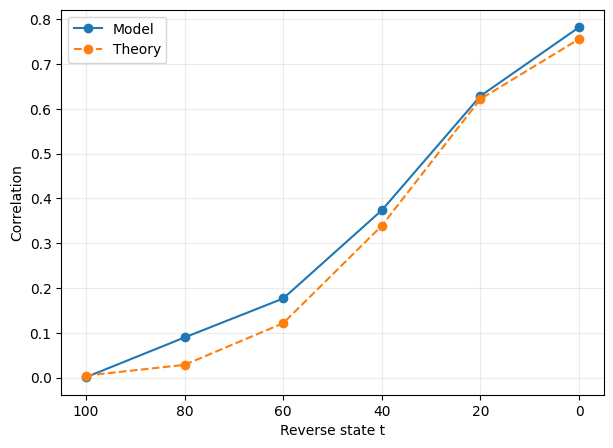

In [62]:
def kurt(x):
    c=x-x.mean(); v=np.mean(c*c); return np.mean(c**4)/(v*v)-3
@torch.no_grad()
def sample(n=10000):
    g=torch.Generator(device=device).manual_seed(SEED+1000); x=torch.randn((n,2),generator=g,device=device); snaps={T:x.cpu().numpy()}
    for s in range(T,0,-1):
        k=s-1; tv=torch.full((n,),k,dtype=torch.long,device=device); pred=model(x,tv)
        # TODO 5-A: reverse mean
        mean = (x - betas[k] / torch.sqrt(1 - alpha_bar_full[s]) * pred) / torch.sqrt(alphas[k])
        assert mean is not None
        if s==1:
            x=mean
        else:
            # TODO 5-B: stochastic transition
            beta_tilde = (1 - alpha_bar_full[s-1]) / (1 - alpha_bar_full[s]) * betas[k]
            x = mean + torch.sqrt(beta_tilde) * torch.randn((n,2),generator=g,device=device)
            assert x is not None
        if s-1 in [80,60,40,20,0]: snaps[s-1]=x.cpu().numpy()
    return x.cpu().numpy(),snaps
gen_z,snaps=sample(); rho0=np.corrcoef(z_np.T)[0,1]; k10=kurt(z_np[:,0]); k20=kurt(z_np[:,1]); rr=[]
for s,a in sorted(snaps.items(),reverse=True):
    q=float(alpha_bar_full[s]); rr.append([s,np.corrcoef(a.T)[0,1],q*rho0,kurt(a[:,0]),q*q*k10,kurt(a[:,1]),q*q*k20])
trajectory_table=pd.DataFrame(rr,columns=["state_t","corr_model","corr_theory","kurt1_model","kurt1_theory","kurt2_model","kurt2_theory"]); display(trajectory_table)
plt.figure(figsize=(7,5)); plt.plot(trajectory_table.state_t,trajectory_table.corr_model,"o-",label="Model"); plt.plot(trajectory_table.state_t,trajectory_table.corr_theory,"o--",label="Theory"); plt.gca().invert_xaxis(); plt.xlabel("Reverse state t"); plt.ylabel("Correlation"); plt.legend(); plt.grid(alpha=.25); plt.show()

### 결과해석
비교 기준(theory)은 상관계수 $q\rho_0$, 초과첨도 $q^2\kappa_0$입니다($q=\bar\alpha_t$). $t=0$에서 theory는 실제 데이터 값(상관 0.756, 첨도 13.4, 7.3)과 같습니다.

**1. 상관계수**

| t | Model | Theory | 차이 |
|---|---|---|---|
| 100 | 0.001 | 0.004 | -0.004 |
| 80 | 0.089 | 0.028 | +0.061 |
| 60 | 0.176 | 0.121 | +0.055 |
| 40 | 0.374 | 0.339 | +0.035 |
| 20 | 0.629 | 0.622 | +0.007 |
| 0 | 0.782 | 0.756 | +0.026 |

- 경로의 전체 형태는 이론과 잘 맞습니다. 0에서 출발해 실제 상관 근처까지 단조롭게 회복하고, 최종 상관 0.782는 실제 0.756의 약 1.03배입니다.
- t=100(둘 다 거의 0)을 제외한 모든 state에서 Model이 Theory보다 높습니다. 차이는 중간 구간(t=80, 60)에서 0.05~0.06으로 가장 크고, 최종에서도 +0.026이 남습니다. 모델이 의존 구조를 이론보다 조금 일찍, 조금 강하게 만듭니다.

**2. 초과첨도**

| t | Asset1 Model / Theory | Asset2 Model / Theory |
|---|---|---|
| 100 | 0.027 / 0.0004 | 0.036 / 0.0002 |
| 80 | 0.24 / 0.019 | 0.27 / 0.010 |
| 60 | 1.14 / 0.35 | 0.61 / 0.19 |
| 40 | 5.5 / 2.7 | 2.4 / 1.5 |
| 20 | 13.4 / 9.1 | 10.9 / 4.9 |
| 0 | 23.6 / 13.4 | 17.3 / 7.3 |

- 모든 state에서 Model의 첨도가 theory보다 큽니다. t=0에서 Asset 1은 약 1.76배, Asset 2는 약 2.4배로, 생성 표본의 꼬리가 실제 데이터보다 두껍습니다.
- t=100의 0.03 내외는 Gaussian 표본 10000개의 첨도 표준오차(약 0.05) 안이므로 표본 오차 수준입니다. 반면 t=80 이후의 차이는 이를 넘는 실제 편차입니다.
- 상관계수보다 첨도의 편차가 훨씬 큽니다. 첨도는 꼬리의 극단값에 민감한 통계량이라 작은 오차도 크게 반영합니다.

**3. 편차 원인 구분**
이 표만으로 원인을 확정할 수는 없고, 후보는 다음과 같습니다.

- **Model error**: Part 3에서 큰 t의 ε 오차가 Gaussian보다 컸고, 이 오차가 reverse 단계마다 누적됩니다.
- **Discretization**: T=100이고 β가 최대 0.1이라 step이 커서 Gaussian reverse 근사가 거칩니다.
- **Reverse variance specification**: 이 구현은 $\tilde\beta_t$를 썼고, $\sigma_t^2=\beta_t$를 쓰면 주입되는 노이즈가 달라집니다.
- **Finite-sample error**: n=10000이며 첨도는 꼬리 표본에 민감합니다.

첨도 편차가 두 자산에서 모든 state에 걸쳐 같은 방향으로 크므로 표본 오차만으로는 설명하기 어렵고, 체계적 요인(model error, 분산 설정, discretization)이 작용한 것으로 보입니다. 어느 요인이 지배적인지는 분산 설정이나 seed를 바꾸는 ablation으로 구분해야 합니다.

**결론**: 이 pair는 상관이 높아(ρ=0.756) recovery ratio로 비교할 수 있으며, 상관 회복 비율은 약 1.03으로 양호합니다. 반면 꼬리(첨도)는 실제보다 과대하게 생성되었습니다.


# Part 6. Real vs MVN vs One-shot vs DDPM

최종 tail 비교는 원래 return 단위로 역변환하여 수행합니다.

In [63]:
def met(x,q):
    return dict(std1=x[:,0].std(),std2=x[:,1].std(),corr=np.corrcoef(x.T)[0,1],kurt1=kurt(x[:,0]),kurt2=kurt(x[:,1]),q01_1=np.quantile(x[:,0],.01),q01_2=np.quantile(x[:,1],.01),joint=np.mean((x[:,0]<q[0])&(x[:,1]<q[1])))
q05=np.quantile(raw,.05,axis=0); gen=gen_z*sigma+mu
rng2=np.random.default_rng(SEED+2000); mvn=rng2.multivariate_normal(raw.mean(0),np.cov(raw.T,ddof=0),10000)
g=torch.Generator(device=device).manual_seed(SEED+3000); xT=torch.randn((10000,2),generator=g,device=device); tv=torch.full((10000,),T-1,dtype=torch.long,device=device)
with torch.no_grad(): eh=model(xT,tv)
q=alpha_bar_full[T]; one=((xT-torch.sqrt(1-q)*eh)/torch.sqrt(q)).cpu().numpy()*sigma+mu
finance_table=pd.DataFrame([{"distribution":n,**met(a,q05)} for n,a in [("REAL",raw),("MVN",mvn),("ONE_SHOT",one),("DDPM",gen)]]); display(finance_table)
print("WEEK04_CORE_RESULTS_PASS")

,distribution,std1,std2,corr,kurt1,kurt2,q01_1,q01_2,joint
0,REAL,0.021063,0.025852,0.755927,13.446659,7.253052,-0.056669,-0.062530,0.025086
1,MVN,0.021065,0.025816,0.755995,0.066117,0.043455,-0.050614,-0.059663,0.034700
2,ONE_SHOT,0.024216,0.018874,0.588062,24.331301,16.373430,-0.067549,-0.054659,0.014700
3,DDPM,0.021519,0.025251,0.782271,23.632047,17.283711,-0.057810,-0.068936,0.031600


WEEK04_CORE_RESULTS_PASS


### 결과해석
값은 원래 수익률 단위이며, REAL과 얼마나 가까운지가 비교 기준입니다.

| 항목 | REAL | MVN | ONE_SHOT | DDPM |
|---|---|---|---|---|
| std1 | 0.0211 | 0.0211 | 0.0242 (+15%) | 0.0215 (+2%) |
| std2 | 0.0259 | 0.0258 | 0.0189 (−27%) | 0.0253 (−2%) |
| corr | 0.756 | 0.756 | 0.588 | 0.782 |
| kurt1 | 13.4 | 0.07 | 24.3 | 23.6 |
| kurt2 | 7.3 | 0.04 | 16.4 | 17.3 |
| q01_1 | −0.0567 | −0.0506 | −0.0675 | −0.0578 |
| q01_2 | −0.0625 | −0.0597 | −0.0547 | −0.0689 |
| joint | 0.0251 | 0.0347 | 0.0147 | 0.0316 |

**1. 방법별 진단**

- **MVN**: std와 corr는 실제 데이터의 2차 모멘트로 맞춘 것이라 거의 정확히 일치합니다. 반면 첨도가 0.07, 0.04로 실제의 fat tail(13.4, 7.3)을 전혀 재현하지 못하며, 1% 분위수도 실제보다 덜 극단적입니다(Asset 1: −0.0506 대 −0.0567).
- **ONE_SHOT**: 전반적으로 가장 나쁩니다. 상관이 0.588로 크게 낮고, std는 한 자산이 +15%, 다른 자산이 −27%로 어긋나며, joint는 0.0147로 실제의 약 59% 수준입니다. 첨도 24.3, 16.4가 높은 것은 꼬리를 학습한 결과가 아니라 t=100에서 ε 예측 오차가 A_t=13.3배로 증폭된 결과(Part 4)로 보는 것이 타당합니다.
- **DDPM**: std는 ±2% 이내로 잘 맞습니다. 상관은 0.782로 실제보다 0.026 높고(Part 5와 동일), 첨도는 23.6, 17.3으로 fat tail 자체는 재현하지만 실제의 약 1.76배, 2.38배로 과대합니다.

**2. DDPM과 MVN의 비교**

| 특성 | 더 가까운 쪽 | 근거 |
|---|---|---|
| std, corr | MVN | MVN은 모멘트를 직접 맞춘 구조라 오차가 거의 0. DDPM은 std ±2%, corr +0.026 |
| 첨도 (fat tail의 존재) | **DDPM** | MVN은 사실상 0이라 꼬리가 있다는 사실 자체를 놓침 |
| 첨도 (크기) | 자산별로 다름 | 절대오차 Asset 1: DDPM 10.2 대 MVN 13.4, Asset 2: DDPM 10.0 대 MVN 7.2 |
| q01 | 자산별로 다름 | 절대오차 Asset 1: DDPM 0.0011 대 MVN 0.0061, Asset 2: DDPM 0.0064 대 MVN 0.0029 |
| joint | DDPM (소폭) | 오차 0.0065 대 0.0096. 표본 오차(약 0.002~0.003)를 감안하면 차이는 크지 않음 |

**3. 결론**
DDPM이 MVN보다 확실히 낫다고 말할 수 있는 특성은 **fat tail이 존재한다는 점(첨도 > 0)** 하나입니다. 꼬리의 크기는 과대하게 생성되고, 1% 분위수는 자산에 따라 우열이 갈리며, joint tail은 약간 가깝지만 표본 오차 범위에 가깝습니다. std와 상관은 오히려 MVN이 더 낫습니다. 따라서 "DDPM이 Gaussian보다 더 많은 금융분포 구조를 학습했다"는 주장은 꼬리 형태의 존재라는 제한된 의미에서만 성립하며, 정량적 재현에서는 일관되게 우세하지 않습니다. 이는 Part 3(Neural과 Gaussian denoiser가 거의 비슷한 수준)과 Part 5(첨도 과대)의 결과와 같은 방향입니다.

**4. 한계**
한 번의 샘플링(n=10000, seed 하나) 결과이며, 첨도와 joint는 표본에 민감해 차이가 작은 항목은 seed를 바꾸면 우열이 뒤집힐 수 있습니다.


# Final Assignment
**Q1.** Neural vs Gaussian denoiser 결과를 설명하세요.

**Q2.** One-shot 결과가 contraction/amplification 중 어느 영역인지 진단하세요.

**Q3.** Reverse trajectory를 theoretical benchmark와 비교하고 편차 원인을 구분하세요. LOW-correlation pair에서는 recovery ratio보다 absolute deviation을 사용하세요.

**Q4.** Real / MVN / One-shot / DDPM을 비교하여 DDPM이 Gaussian보다 더 잘 재현한 금융분포 특성이 있는지, 없다면 없다고 결론내리세요.

**[YOUR ANSWER]**

**Q1. Neural vs Gaussian denoiser**

t=10, 30, 50에서 Neural의 ε RMSE가 Gaussian보다 낮았습니다(0.951 대 0.956, 0.713 대 0.738, 0.487 대 0.509). t=70에서는 0.286 대 0.287로 동률이었고, t=90, 100에서는 Gaussian이 더 낮았습니다(0.126 대 0.149, 0.077 대 0.103). Neural의 개선폭은 최대 약 4%로 작아서, P06의 fat tail을 일부 반영하는 데 그친 것으로 보입니다.

x₀ RMSE는 $A_t\times$ ε RMSE로 증폭됩니다. Neural는 t=70(0.958)에서는 1 미만이었고 t=90(1.19), t=100(1.37)에서 1을 넘어 x₀=0 예측보다 나빠졌습니다(측정점 사이의 교차점은 선형보간 시 약 t≈74). 큰 t에서는 $x_t$가 거의 순수 노이즈($\Sigma_t\approx I$)라서 Gaussian 공식이 거의 정확한 반면, 신경망은 작은 잔여 오차가 남고 그것이 $A_t$=8~13배로 증폭됩니다. 따라서 DDPM이 항상 Gaussian보다 우월하다고 말할 수 없습니다.

**Q2. One-shot 진단**

variance ratio는 t=30, 50에서 Asset 1이 1.21, 1.39, Asset 2가 0.92, 0.89로 1 근처이고, t=70에서 2.36, 1.32로 증폭이 시작되며, t=100에서 158.8, 63.3으로 폭발합니다. t=100에서 사후평균의 분산은 약 0.009로 거의 0으로 수축해야 하는데, one-shot 추정값의 분산은 약 1.4(Asset 1)로 원본 분산 1을 넘었습니다. 따라서 큰 t에서는 posterior-mean contraction이 아니라 **model-error amplification이 지배적**인 영역입니다. 작은~중간 t(30~50)는 수축과 모델 오차가 대체로 균형을 이루는 구간입니다.

**Q3. Reverse trajectory와 편차 원인**

P06은 상관이 높은 pair($\rho$=0.756)라서 recovery ratio로 비교했습니다. 상관은 t=0에서 0.782로 실제의 약 1.03배(차이 +0.026)이고, 중간 구간(t=80, 60)에서 이론보다 0.05~0.06 높았습니다. 초과첨도는 모든 state에서 theory보다 크며, t=0에서 Asset 1은 23.6(실제 13.4), Asset 2는 17.3(실제 7.3)으로 각각 약 1.76배, 2.38배입니다.

편차 원인의 후보는 다음과 같습니다.
- **Model error**: 큰 t에서 ε 예측 오차(Part 3)가 reverse 단계마다 누적됩니다.
- **Discretization**: T=100, $\beta$ 최대 0.1로 step이 커서 Gaussian 근사가 거칩니다.
- **Reverse variance specification**: $\tilde\beta_t$ 대신 $\beta_t$를 쓰면 주입되는 노이즈 양이 달라집니다.
- **Finite-sample error**: n=10000에서 첨도는 꼬리 표본에 민감합니다. 다만 t=100의 첨도(0.03 내외)는 표본 오차 수준이지만, t=80 이후의 차이는 이를 넘습니다.

첨도 편차가 두 자산에서 모든 state에 걸쳐 같은 방향으로 크므로 표본 오차만으로는 설명하기 어렵고 체계적 요인이 작용한 것으로 보입니다. 어느 요인이 지배적인지는 분산 설정과 seed를 바꾸는 ablation 없이는 구분할 수 없습니다.

**Q4. Real / MVN / One-shot / DDPM 비교**

| 특성 | 결과 |
|---|---|
| std, corr | MVN이 더 가깝습니다(모멘트를 직접 맞춘 구조). DDPM은 std ±2%, corr +0.026 |
| 첨도 | MVN은 0.07, 0.04로 fat tail을 놓칩니다. DDPM은 23.6, 17.3으로 꼬리는 재현하지만 각각 1.76배, 2.38배 과대합니다 |
| q01 | Asset 1은 DDPM이 가깝고(오차 0.0011 대 0.0061), Asset 2는 MVN이 가깝습니다(0.0029 대 0.0064) |
| joint | DDPM이 소폭 가깝지만(오차 0.0065 대 0.0096) 표본 오차 범위에 가깝습니다 |
| One-shot | 상관 0.588, std −27%~+15%로 전반적으로 가장 나쁩니다 |

**결론**: DDPM이 Gaussian(MVN)보다 확실히 더 잘 재현한 특성은 **fat tail이 존재한다는 점(첨도 > 0)** 하나입니다. 꼬리의 크기는 과대하게 생성되고, 1% 분위수는 자산에 따라 우열이 갈리며, joint tail은 약간 가깝지만 표본 오차 범위에 가깝습니다. std와 상관은 오히려 MVN이 더 낫습니다. 따라서 "내 DDPM이 Gaussian보다 실제로 더 많은 금융분포 구조를 학습했다"는 주장은 꼬리 형태의 존재라는 제한된 의미에서만 성립하고, 정량적으로는 일관되게 우세하지 않습니다. 다만 단일 seed(n=10000) 결과라는 한계가 있습니다.


In [64]:
required=[oracle_table,denoiser_table,one_table,trajectory_table,finance_table]
assert all(len(x)>0 for x in required)
print("DIFFUSION_WEEK04_LAB_ASSIGNMENT_PASS")

DIFFUSION_WEEK04_LAB_ASSIGNMENT_PASS
